In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, BACKENDS, metrics_table, table
from strahler.widgets import GameView, TreeView, Stepper
from IPython.display import display

strahler package and library versions match


# Step through lifting

Inspect a Strahler host, adaptive t, and iterative shaving (`+iter`). Each
Stepper badge calls the public `materialize_partial` function before checking
the candidate. Structural problems from the materializer and validity failures
from `check()` are separate diagnostics. A candidate can fail before convergence;
unresolved vertices remain undecided. Root S labels mean TOP and are not part
of the final certified region.

In [2]:
from otj22 import hk, hk_coordinates
game = strahler.Game.from_text(hk(2))
configurations = {
    "Strahler": {"tree_k": 2},
    "adaptive t": {"adaptive_t": True},
    "adaptive t +iter": {"adaptive_t": "incremental", "iter_shave": True},
}
steppers = {}
for name, options in configurations.items():
    stepper = Stepper(strahler.trace(game, "lifting", **options), hk_coordinates(2))
    steppers[name] = stepper
    display(stepper)
    for kind in ("lift", "round_end", "phase"):
        stepper.seek(0)
        stepper.next(kind)
        for player in range(2):
            verdict = stepper.verify(player)
            print(name, kind, player, verdict)
    stepper.end()
    assert stepper.run.result.complete
    assert all(stepper.verify(p).ok for p in range(2))
metrics_table({name: stepper.run.result for name, stepper in steppers.items()})

Static widget snapshot; rerun for interactive controls.

Strahler lift 0 CheckResult(ok=False, condition=<Condition.TOP: 5>, path=(), vertex=1, message='the stored top attractor is incorrect', violations=(Violation(condition=<Condition.TOP: 5>, path=(), vertex=1, edge=None), Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=0, edge=None), Violation(condition=<Condition.PARTITION: 10>, path=(), vertex=0, edge=None)))
Strahler lift 1 CheckResult(ok=False, condition=<Condition.INPUT: 1>, path=(), vertex=None, message='nonempty subgame has no decomposition', violations=(Violation(condition=<Condition.INPUT: 1>, path=(), vertex=None, edge=None),))
Strahler round_end 0 CheckResult(ok=False, condition=<Condition.TRAP: 7>, path=(0,), vertex=3, message='a child is not a nonempty opponent trap', violations=(Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=3, edge=(3, 2)), Violation(condition=<Condition.ATTRACTOR: 9>, path=(0,), vertex=5, edge=None), Violation(condition=<Condition.PARTITION: 10>, path=(), vertex=5, edge=None)))
Strah

Static widget snapshot; rerun for interactive controls.

adaptive t lift 0 CheckResult(ok=False, condition=<Condition.TOP: 5>, path=(), vertex=1, message='the stored top attractor is incorrect', violations=(Violation(condition=<Condition.TOP: 5>, path=(), vertex=1, edge=None), Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=0, edge=None), Violation(condition=<Condition.PARTITION: 10>, path=(), vertex=0, edge=None)))
adaptive t lift 1 CheckResult(ok=False, condition=<Condition.INPUT: 1>, path=(), vertex=None, message='nonempty subgame has no decomposition', violations=(Violation(condition=<Condition.INPUT: 1>, path=(), vertex=None, edge=None),))
adaptive t round_end 0 CheckResult(ok=False, condition=<Condition.TRAP: 7>, path=(0,), vertex=3, message='a child is not a nonempty opponent trap', violations=(Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=3, edge=(3, 2)), Violation(condition=<Condition.ATTRACTOR: 9>, path=(0,), vertex=5, edge=None), Violation(condition=<Condition.PARTITION: 10>, path=(), vertex=5, edge=None)))

Static widget snapshot; rerun for interactive controls.

adaptive t +iter lift 0 CheckResult(ok=False, condition=<Condition.TOP: 5>, path=(), vertex=1, message='the stored top attractor is incorrect', violations=(Violation(condition=<Condition.TOP: 5>, path=(), vertex=1, edge=None), Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=0, edge=None), Violation(condition=<Condition.PARTITION: 10>, path=(), vertex=0, edge=None)))
adaptive t +iter lift 1 CheckResult(ok=False, condition=<Condition.INPUT: 1>, path=(), vertex=None, message='nonempty subgame has no decomposition', violations=(Violation(condition=<Condition.INPUT: 1>, path=(), vertex=None, edge=None),))
adaptive t +iter round_end 0 CheckResult(ok=False, condition=<Condition.TRAP: 7>, path=(0,), vertex=3, message='a child is not a nonempty opponent trap', violations=(Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=3, edge=(3, 2)), Violation(condition=<Condition.ATTRACTOR: 9>, path=(0,), vertex=5, edge=None), Violation(condition=<Condition.PARTITION: 10>, path=(), vert

backend,player,nodes,leaves,height,Strahler,dominion,won,complete,unresolved
Strahler,Even,3,2,2,2,5,5,True,0
Strahler,Odd,3,2,2,2,5,5,True,0
adaptive t,Even,3,2,2,2,5,5,True,0
adaptive t,Odd,3,2,2,2,5,5,True,0
adaptive t +iter,Even,2,1,2,1,2,5,True,0
adaptive t +iter,Odd,2,1,2,1,2,5,True,0


dominion: vertices covered by this player's attractor decomposition (its tree); won: every vertex this player wins, including vertices removed by preprocessing (+pre) or earlier shaving rounds (+iter); unresolved: vertices neither player's search certified.


Structural problems: [{'ok': False, 'condition': 22, 'path': [0], 'vertex': 1, 'message': 'a nonempty c+ fibre has an empty child core'}, {'ok': False, 'condition': 22, 'path': [1], 'vertex': 2, 'message': 'a nonempty c+ fibre has an empty child core'}]
Independent verdict: CheckResult(ok=False, condition=<Condition.TOP: 5>, path=(), vertex=0, message='the stored top attractor is incorrect', violations=(Violation(condition=<Condition.TOP: 5>, path=(), vertex=0, edge=None), Violation(condition=<Condition.TRAP: 7>, path=(0,), vertex=None, edge=None), Violation(condition=<Condition.ATTRACTOR: 9>, path=(0,), vertex=1, edge=(1, 1)), Violation(condition=<Condition.TRAP: 7>, path=(1,), vertex=None, edge=None), Violation(condition=<Condition.ATTRACTOR: 9>, path=(1,), vertex=2, edge=(2, 2)), Violation(condition=<Condition.PARTITION: 10>, path=(), vertex=0, edge=None)))


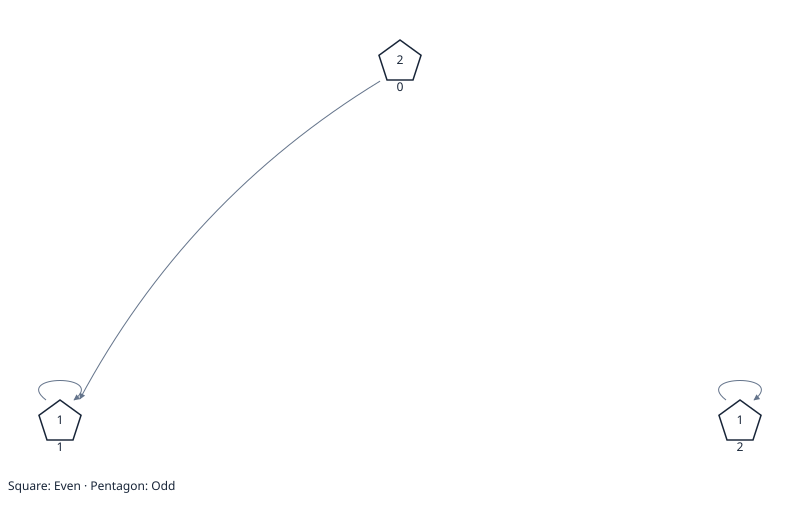

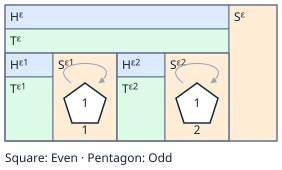

In [3]:
# Public materializer example: S parts with empty child cores.
partial_game = strahler.Game.from_text('0 2 1 1; 1 1 1 1; 2 1 1 2;')
labels = dict(player=0, h=2, tree="0|1|", labels=[
    dict(vertex=1, path=[0], part="S"), dict(vertex=2, path=[1], part="S")])
partial = strahler.materialize_partial(partial_game, labels)
assert [problem["condition"] for problem in partial["problems"]] == [22, 22]
print("Structural problems:", partial["problems"])
print("Independent verdict:", strahler.check(partial_game, partial["tree"], 0))
view = GameView(partial_game)
display(view, TreeView(partial["tree"], view))